labeling drought

لیبلینگ پاییز شمال غرب

In [2]:
from google.colab import files
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.semi_supervised import SelfTrainingClassifier
from google.colab import files
# ⬆️ آپلود فایل داده
uploaded = files.upload()

# 📥 خواندن فایل
for fname in uploaded.keys():
    df = pd.read_csv(fname)
    file_name = fname
    break


Saving SPRINGnw.csv to SPRINGnw.csv


In [3]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.semi_supervised import SelfTrainingClassifier
from google.colab import files

# 🎯 ویژگی‌های مؤثر در خشکسالی اقلیم خوزستان در فصل بهار
features = ["t2m_anom", "swvl1_anom", "VPD_anom", "spi_seasonal"]

# 🧹 حذف داده‌های ناقص
df = df.dropna(subset=features).copy()

# 🏷️ تعریف ستون برچسب خشکسالی
df["hazard_drought"] = np.nan

# ✅ تعریف علمی برچسب خشکسالی بر اساس تحلیل آماری و منابع اقلیمی
mask_drought = (
    (df["spi_seasonal"] <= -1.0) &         # خشکسالی متوسط به بالا
    (df["tp"] <= 0.7 * df["tp"].mean()) &  # بارش کمتر از 70٪ میانگین → بررسی محلی
    (df["t2m_anom"] >= 0.8) &              # افزایش دما → افزایش تبخیر
    (df["VPD_anom"] >= 0.8) &              # خشکی هوا
    (df["swvl1_anom"] <= -0.5)             # کمبود رطوبت خاک
)

# ✅ تعریف نرمال (بهار بدون تنش خشکی)
mask_normal = (
    (df["spi_seasonal"] > -0.4) &
    (df["tp"] >= 0.95 * df["tp"].mean()) &
    (df["t2m_anom"] < 0.5) &
    (df["VPD_anom"] < 0.5) &
    (df["swvl1_anom"] > -0.2)
)

# 🏷️ برچسب‌گذاری اولیه
df.loc[mask_drought, "hazard_drought"] = 1
df.loc[mask_normal, "hazard_drought"] = 0

# ℹ️ گزارش اولیه
print("✅ نمونه‌های اولیه خشکسالی:", df["hazard_drought"].eq(1).sum())
print("✅ نمونه‌های اولیه نرمال:", df["hazard_drought"].eq(0).sum())
print("❔ نمونه‌های بدون برچسب:", df["hazard_drought"].isna().sum())

# 📦 آماده‌سازی مدل نیمه‌نظارتی
X_all = df[features]
y_all = df["hazard_drought"]

labeled_mask = y_all.notna()
X_labeled = X_all[labeled_mask]
y_labeled = y_all[labeled_mask].astype(int)
X_unlabeled = X_all[~labeled_mask]

# 🧠 مدل پایه
base_model = DecisionTreeClassifier(max_depth=4, criterion='gini', random_state=42)

# 🧠 Self-Training با آستانه اطمینان بالا
self_training_model = SelfTrainingClassifier(
    estimator=base_model,  # ✅ به‌روز شده برای sklearn جدید
    threshold=0.85,
    verbose=True
)

# 🎓 آموزش و پیش‌بینی
self_training_model.fit(X_labeled, y_labeled)
df.loc[~labeled_mask, "hazard_drought"] = self_training_model.predict(X_unlabeled)

# 💾 ذخیره خروجی
output_file = "/content/labeled_" + file_name
df.to_csv(output_file, index=False)

print("📊 نهایی:")
print("✅ خشکسالی:", df["hazard_drought"].eq(1).sum())
print("✅ نرمال:", df["hazard_drought"].eq(0).sum())
print("❔ بدون برچسب:", df["hazard_drought"].isna().sum())



✅ نمونه‌های اولیه خشکسالی: 468
✅ نمونه‌های اولیه نرمال: 1482
❔ نمونه‌های بدون برچسب: 4242


/usr/local/lib/python3.11/dist-packages/sklearn/semi_supervised/_self_training.py:288: UserWarning: y contains no unlabeled samples
  warnings.warn("y contains no unlabeled samples", UserWarning)


📊 نهایی:
✅ خشکسالی: 1785
✅ نرمال: 4407
❔ بدون برچسب: 0


In [4]:
import pandas as pd
import numpy as np
from google.colab import files

# 🎯 محاسبه میانگین بلندمدت بارش بهاری (در حالت ساده از همان mean سال استفاده می‌کنیم)
tp_mean = df['tp'].mean()

# 🏷️ تابع علمی‌تر و بومی‌تر برای خشکسالی در خوزستان بهار
def classify_drought_spring_khuzestan(row):
    spi = row['spi_seasonal']
    tp = row['tp']

    # خشکسالی واقعی: هم SPI خیلی پایین، هم بارش خیلی کم
    if spi <= -1.0 and tp <= 0.70 * tp_mean:
        return 1  # خشکسالی شدید یا متوسط

    # شرایط نرمال: هر دو نشانه نرمال یا کمی بالا
    elif spi > -0.4 and tp >= 0.95 * tp_mean:
        return 0  # بهار نرمال

    else:
        return np.nan  # مرزی / نامطمئن

# 🧠 اعمال تابع جدید
df['hazard_drought'] = df.apply(classify_drought_spring_khuzestan, axis=1)

# 💾 ذخیره فایل نهایی
output_path = "/content/labeled_" + file_name
df.to_csv(output_path, index=False)
print("✅ فایل خروجی ذخیره شد:", output_path)




✅ فایل خروجی ذخیره شد: /content/labeled_SPRINGnw.csv


In [5]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from google.colab import files

# 🎯 ویژگی‌های بهینه برای خشکسالی در بهار خوزستان
features = ['t2m', 't2m_anom', 'tp', 'tp_anom', 'spi_seasonal',
            'swvl1_anom', 'VPD_anom', 'GDD']  # swvl2_anom و ssrd_anom حذف شدند

X = df[features]
y = df['hazard_drought']

# 📌 داده‌های دارای برچسب
X_train = X[y.notna()]
y_train = y[y.notna()].astype(int)

# داده‌های بدون برچسب
X_unlabeled = X[y.isna()]

# 📦 مدل XGBoost
model = XGBClassifier(max_depth=3, n_estimators=100,
                      use_label_encoder=False, eval_metric='logloss')
model.fit(X_train, y_train)

# 🔮 پیش‌بینی بر روی داده‌های بدون برچسب
probs = model.predict_proba(X_unlabeled)[:, 1]
labels = np.where(probs >= 0.8, 1, np.where(probs <= 0.3, 0, np.nan))
df.loc[y.isna(), 'hazard_drought'] = labels

# 📊 گزارش نتایج برچسب‌گذاری
print("🔍 پیش‌بینی‌شده خشکسالی:", np.sum(labels == 1))
print("🔍 پیش‌بینی‌شده نرمال:", np.sum(labels == 0))
print("🔍 برچسب‌نشده باقی‌مانده:", np.sum(np.isnan(labels)))

# 💾 ذخیره فایل خروجی
output_file = "/content/labeled_" + file_name
df.to_csv(output_file, index=False)
print("✅ فایل خروجی ذخیره شد:", output_file)


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [03:24:38] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


🔍 پیش‌بینی‌شده خشکسالی: 760
🔍 پیش‌بینی‌شده نرمال: 914
🔍 برچسب‌نشده باقی‌مانده: 1436
✅ فایل خروجی ذخیره شد: /content/labeled_SPRINGnw.csv


In [6]:
import pandas as pd
import numpy as np
from google.colab import files

# 📊 تعیین آستانه‌های آماری از داده واقعی
tp_50 = df['tp'].quantile(0.50)
tp_25 = df['tp'].quantile(0.25)

# 💧 تعریف شرایط کسری بارش:
# 1. بارش بین صدک 25 و 50 (نسبتاً کم ولی نه بحرانی)
# 2. SPI بین -1.3 و -0.5 → نشان‌دهنده خشکی نسبی اما نه خشکسالی شدید
condition_tp = (df['tp'] <= tp_50) & (df['tp'] > tp_25)
condition_spi = (df['spi_seasonal'] >= -1.3) & (df['spi_seasonal'] <= -0.5)

# 🏷️ ترکیب و برچسب‌گذاری
df['hazard_rain_deficit'] = np.where(condition_tp & condition_spi, 1, 0)

# 💾 ذخیره خروجی
output_file = "/content/rain_deficit_" + file_name
df.to_csv(output_file, index=False)
print("✅ فایل با برچسب کسری بارش ذخیره شد:", output_file)



✅ فایل با برچسب کسری بارش ذخیره شد: /content/rain_deficit_SPRINGnw.csv


In [7]:
import pandas as pd
import numpy as np
from google.colab import files

# 🌡️ آستانه‌های موج گرما بهاری خوزستان
t2m_90th = df['t2m'].quantile(0.9)
t2m_anom_75th = df['t2m_anom'].quantile(0.75)

# ✅ شرط موج گرما: دمای مطلق بالا و هم‌زمان آنومالی بالا
condition_heatwave = (
    (df['t2m'] >= t2m_90th) &
    (df['t2m_anom'] >= t2m_anom_75th)
)

# 🏷️ برچسب‌گذاری
df['hazard_heatwave'] = np.where(condition_heatwave, 1, 0)

# 💾 ذخیره فایل خروجی
output_file = "/content/heatwave_" + file_name
df.to_csv(output_file, index=False)
print("✅ فایل با برچسب موج گرما ذخیره شد:", output_file)


✅ فایل با برچسب موج گرما ذخیره شد: /content/heatwave_SPRINGnw.csv


In [8]:
import pandas as pd
import numpy as np
from google.colab import files

# ✅ شرط اصلی: موج گرما + خشکسالی
main_condition = (df['hazard_drought'] == 1) & (df['hazard_heatwave'] == 1)

# ✅ شرط پشتیبان: دما بالا و بارش کم‌تر از نرمال (ترکیبی از مطلق و آنومالی‌ها)
t2m_anom_75th = df['t2m_anom'].quantile(0.75)
tp_25th = df['tp'].quantile(0.25)
spi_dry = df['spi_seasonal'] <= -0.8

supporting_condition = (
    (df['t2m_anom'] >= t2m_anom_75th) &
    (df['tp'] <= tp_25th) &
    (spi_dry)
)

# ✅ ترکیب شرط‌ها
df['hazard_hot_and_dry'] = np.where(main_condition | supporting_condition, 1, 0)

# 💾 ذخیره خروجی
output_file = "/content/hot_and_dry_" + file_name
df.to_csv(output_file, index=False)
print("✅ فایل با برچسب hot_and_dry ذخیره شد:", output_file)



✅ فایل با برچسب hot_and_dry ذخیره شد: /content/hot_and_dry_SPRINGnw.csv


In [9]:
import pandas as pd
import numpy as np
from google.colab import files

# 📊 محاسبه آماره‌های دما
t2m_10th = df['t2m'].quantile(0.10)
t2m_anom_10th = df['t2m_anom'].quantile(0.10)

# ❄️ شرط موج سرما: دما مطلق خیلی پایین + آنومالی منفی بالا
condition = (
    (df['t2m'] <= t2m_10th) &
    (df['t2m_anom'] <= t2m_anom_10th)
)

# 🏷️ برچسب‌گذاری
df['hazard_cold_spell'] = np.where(condition, 1, 0)

# 💾 ذخیره فایل خروجی
output_path = "/content/cold_spell_" + file_name
df.to_csv(output_path, index=False)
print("✅ فایل با برچسب cold spell ذخیره شد:", output_path)



✅ فایل با برچسب cold spell ذخیره شد: /content/cold_spell_SPRINGnw.csv


In [10]:
import pandas as pd
import numpy as np
from google.colab import files

# 📊 محاسبه آماره‌های SSRD و آنومالی
ssrd_10th = df['ssrd'].quantile(0.10)
ssrd_anom_25th = df['ssrd_anom'].quantile(0.25)

# 🔍 تعریف کمبود تابش: SSRD بسیار پایین + آنومالی منفی
condition = (
    (df['ssrd'] <= ssrd_10th) &
    (df['ssrd_anom'] <= ssrd_anom_25th)
)

# 🏷️ برچسب‌گذاری
df['hazard_radiation_deficit'] = np.where(condition, 1, 0)

# 💾 ذخیره فایل نهایی
output_file = "/content/radiation_deficit_" + file_name
df.to_csv(output_file, index=False)
print("✅ فایل با برچسب radiation deficit ذخیره شد:", output_file)



✅ فایل با برچسب radiation deficit ذخیره شد: /content/radiation_deficit_SPRINGnw.csv


In [11]:
import pandas as pd
import numpy as np
from google.colab import files

# 📊 استفاده از صدک برای شناسایی GDD پایین
gdd_25th = df['GDD'].quantile(0.25)

# 🔍 شرط: تجمع دما کمتر از صدک 25ام (پایین‌ترین 25٪ فصل)
condition = df['GDD'] <= gdd_25th

# 🏷️ ایجاد برچسب
df['hazard_temperature_accumulation_deficit'] = np.where(condition, 1, 0)

# 💾 ذخیره خروجی
output_file = "/content/gdd_deficit_" + file_name
df.to_csv(output_file, index=False)
print("✅ فایل با برچسب GDD deficit ذخیره شد:", output_file)


✅ فایل با برچسب GDD deficit ذخیره شد: /content/gdd_deficit_SPRINGnw.csv


🔎 بررسی برچسب: hazard_drought
✅ دارای برچسب 1: 1761
✅ دارای برچسب 0: 2995
❌ NaN: 1436


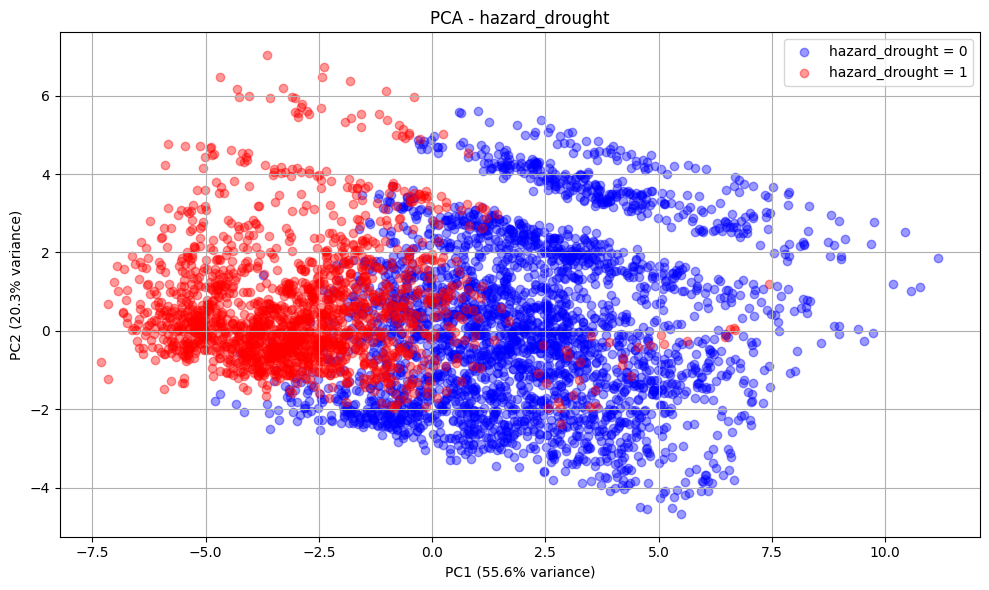

🔎 بررسی برچسب: hazard_rain_deficit
✅ دارای برچسب 1: 247
✅ دارای برچسب 0: 5945
❌ NaN: 0


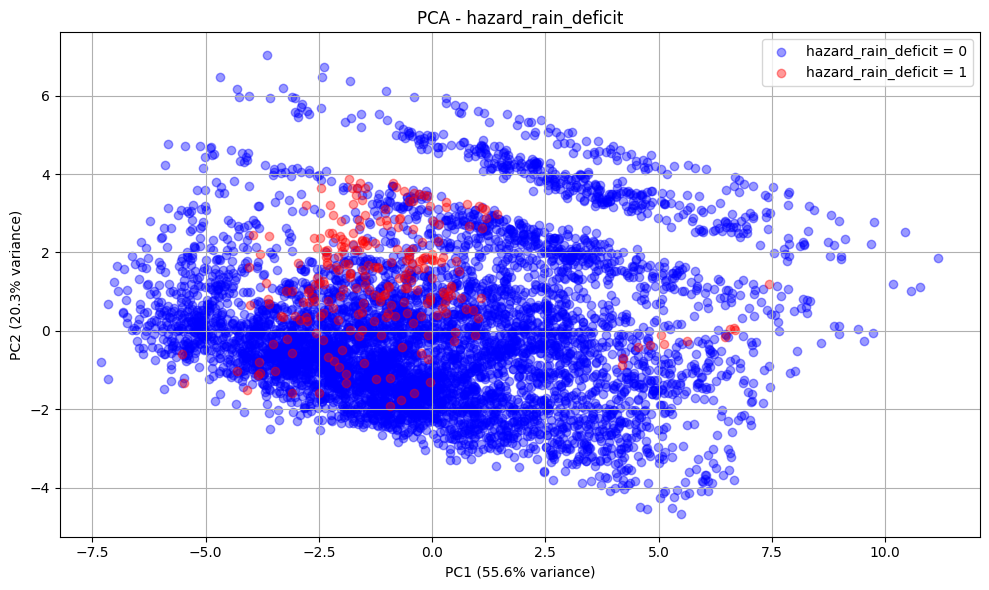

🔎 بررسی برچسب: hazard_heatwave
✅ دارای برچسب 1: 569
✅ دارای برچسب 0: 5623
❌ NaN: 0


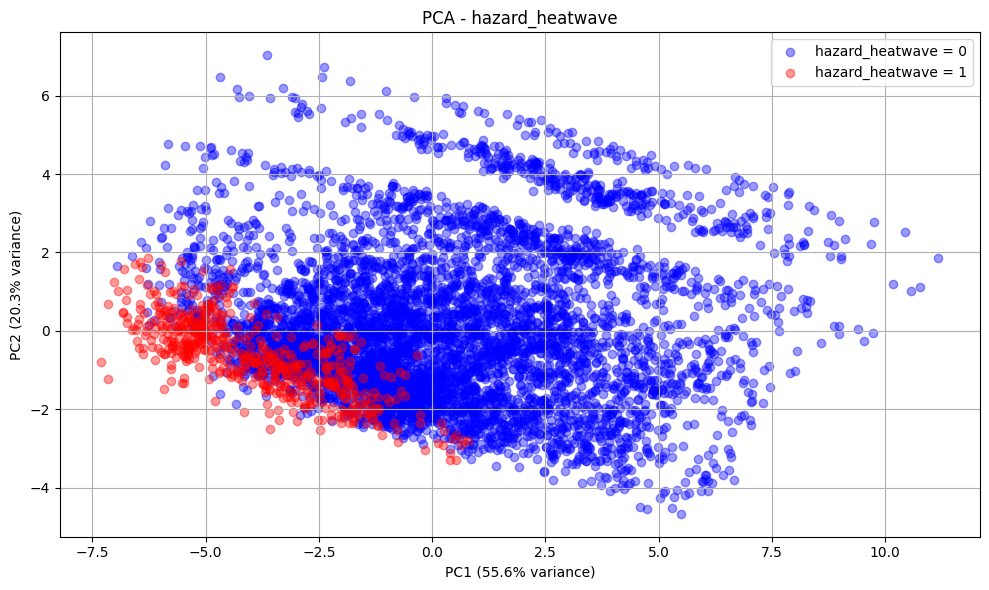

🔎 بررسی برچسب: hazard_hot_and_dry
✅ دارای برچسب 1: 554
✅ دارای برچسب 0: 5638
❌ NaN: 0


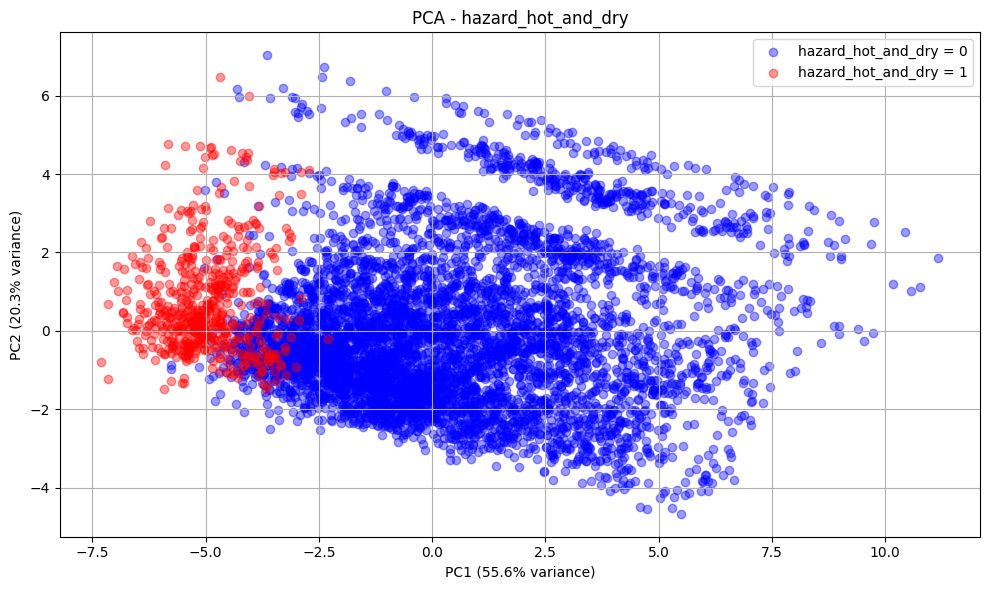

🔎 بررسی برچسب: hazard_cold_spell
✅ دارای برچسب 1: 117
✅ دارای برچسب 0: 6075
❌ NaN: 0


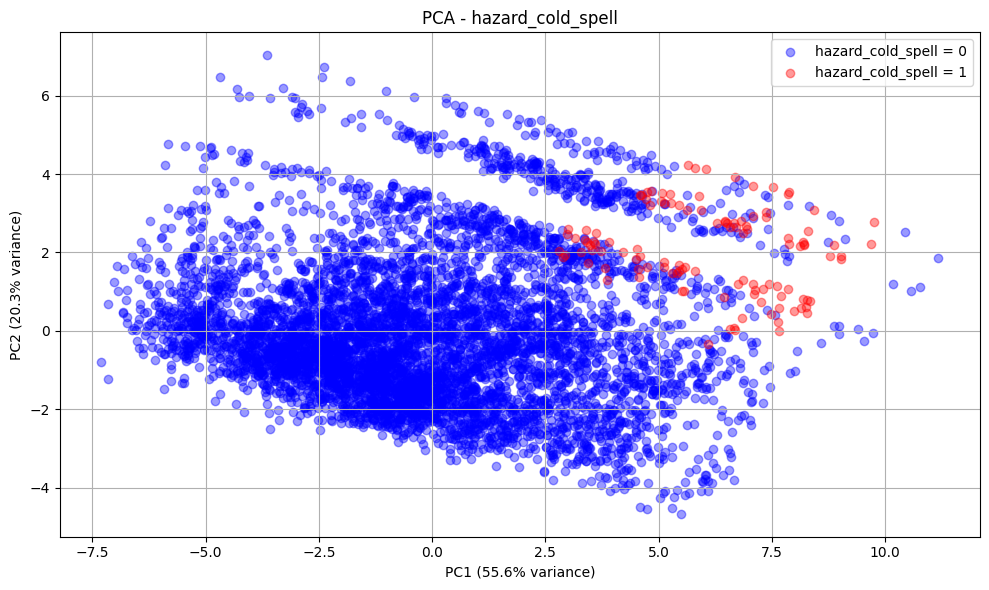

🔎 بررسی برچسب: hazard_radiation_deficit
✅ دارای برچسب 1: 578
✅ دارای برچسب 0: 5614
❌ NaN: 0


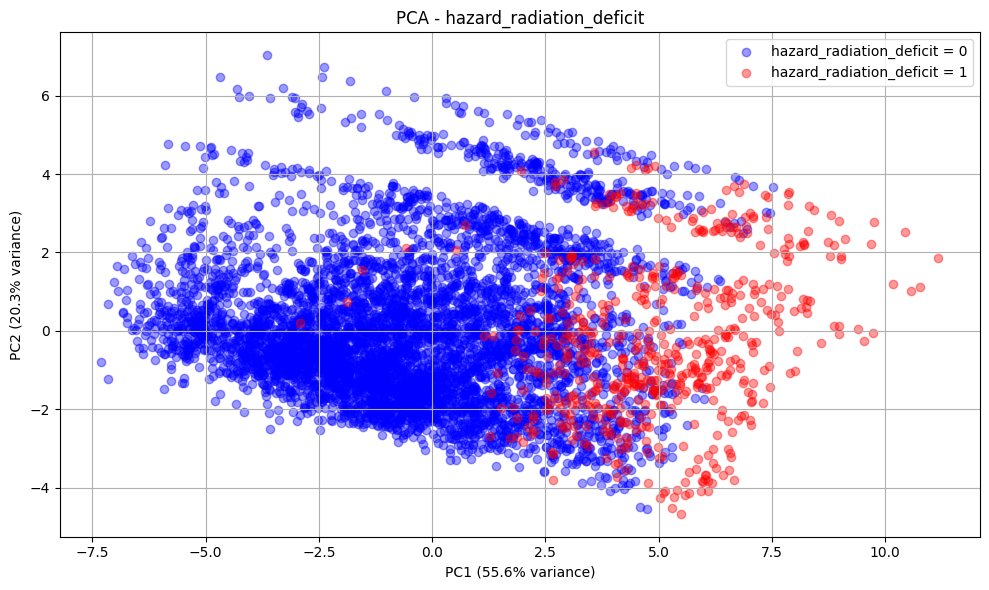

🔎 بررسی برچسب: hazard_temperature_accumulation_deficit
✅ دارای برچسب 1: 1548
✅ دارای برچسب 0: 4644
❌ NaN: 0


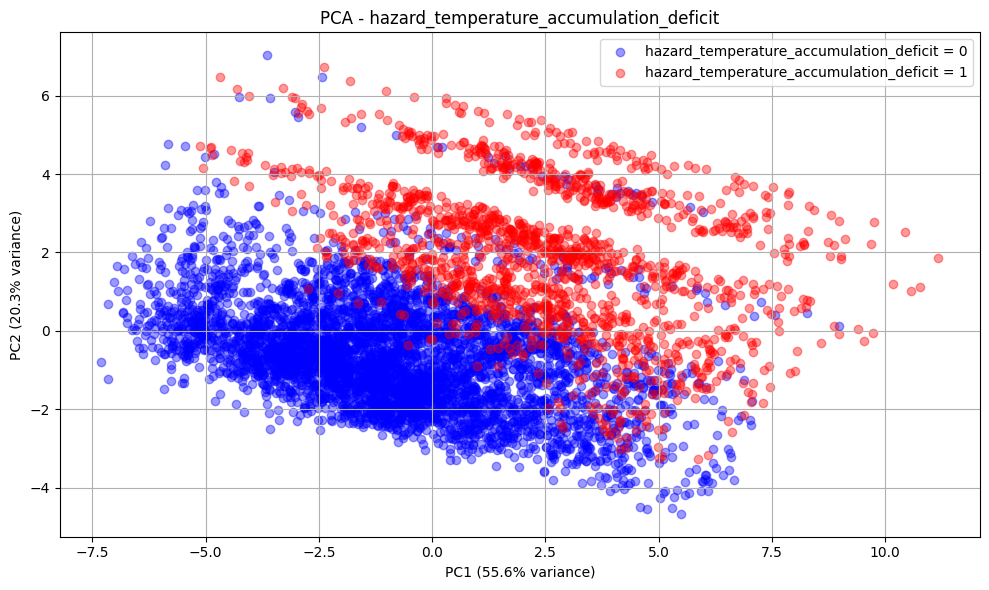

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from google.colab import files

# 🎯 ویژگی‌های عددی
features = [
    't2m', 'tp', 'ssrd', 'swvl1', 'swvl2', 'z', 'RH', 'VPD',
    't2m_anom', 'tp_anom', 'ssrd_anom', 'swvl1_anom', 'swvl2_anom',
    'RH_anom', 'VPD_anom', 'spi_seasonal', 'GDD'
]

# 🧹 حذف ردیف ناقص
df_clean = df.dropna(subset=features)
X = df_clean[features]

# ⚖️ استانداردسازی
X_scaled = StandardScaler().fit_transform(X)

# 🔄 PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
explained_var = pca.explained_variance_ratio_

df_clean["PC1"] = X_pca[:, 0]
df_clean["PC2"] = X_pca[:, 1]

# 🔍 لیست برچسب‌های معتبر: فقط hazard_ که _prob ندارند
hazard_labels = [
    col for col in df.columns
    if col.startswith("hazard_") and not col.endswith("_prob")
]

# 📊 ترسیم بر اساس هر برچسب
for hazard in hazard_labels:
    if hazard not in df_clean.columns:
        continue

    has_data = df_clean[hazard].isin([0, 1]).any()
    if not has_data:
        print(f"⚠️ هیچ مقدار 0 یا 1 برای {hazard} وجود ندارد.")
        continue

    plt.figure(figsize=(10, 6))
    for label in [0, 1]:
        subset = df_clean[df_clean[hazard] == label]
        if not subset.empty:
            plt.scatter(
                subset["PC1"], subset["PC2"],
                c='red' if label == 1 else 'blue',
                alpha=0.4,
                label=f"{hazard} = {label}"
            )

    print(f"🔎 بررسی برچسب: {hazard}")
    print("✅ دارای برچسب 1:", (df_clean[hazard] == 1).sum())
    print("✅ دارای برچسب 0:", (df_clean[hazard] == 0).sum())
    print("❌ NaN:", df_clean[hazard].isna().sum())

    plt.title(f"PCA - {hazard}")
    plt.xlabel(f"PC1 ({explained_var[0]*100:.1f}% variance)")
    plt.ylabel(f"PC2 ({explained_var[1]*100:.1f}% variance)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [13]:
import pandas as pd
import numpy as np

for hazard in hazard_labels:
    if hazard not in df_clean.columns:
        continue

    print(f"📌 تحلیل آماری برچسب: {hazard}")

    for label in [0, 1]:
        subset = df_clean[df_clean[hazard] == label]
        if subset.empty:
            print(f"⚠️ برچسب {label} وجود ندارد.")
            continue

        print(f"\n➡️ Label = {label} | تعداد: {len(subset)}")
        print(f"  ▪️ PC1 → میانگین: {subset['PC1'].mean():.2f}, انحراف معیار: {subset['PC1'].std():.2f}")
        print(f"  ▪️ PC2 → میانگین: {subset['PC2'].mean():.2f}, انحراف معیار: {subset['PC2'].std():.2f}")

    print("\n" + "-" * 60 + "\n")


📌 تحلیل آماری برچسب: hazard_drought

➡️ Label = 0 | تعداد: 2995
  ▪️ PC1 → میانگین: 2.12, انحراف معیار: 2.42
  ▪️ PC2 → میانگین: 0.11, انحراف معیار: 2.09

➡️ Label = 1 | تعداد: 1761
  ▪️ PC1 → میانگین: -2.98, انحراف معیار: 1.99
  ▪️ PC2 → میانگین: 0.58, انحراف معیار: 1.48

------------------------------------------------------------

📌 تحلیل آماری برچسب: hazard_rain_deficit

➡️ Label = 0 | تعداد: 5945
  ▪️ PC1 → میانگین: 0.04, انحراف معیار: 3.10
  ▪️ PC2 → میانگین: -0.05, انحراف معیار: 1.86

➡️ Label = 1 | تعداد: 247
  ▪️ PC1 → میانگین: -1.00, انحراف معیار: 1.99
  ▪️ PC2 → میانگین: 1.28, انحراف معیار: 1.34

------------------------------------------------------------

📌 تحلیل آماری برچسب: hazard_heatwave

➡️ Label = 0 | تعداد: 5623
  ▪️ PC1 → میانگین: 0.39, انحراف معیار: 2.90
  ▪️ PC2 → میانگین: 0.07, انحراف معیار: 1.91

➡️ Label = 1 | تعداد: 569
  ▪️ PC1 → میانگین: -3.89, انحراف معیار: 1.72
  ▪️ PC2 → میانگین: -0.66, انحراف معیار: 0.97

------------------------------------------------

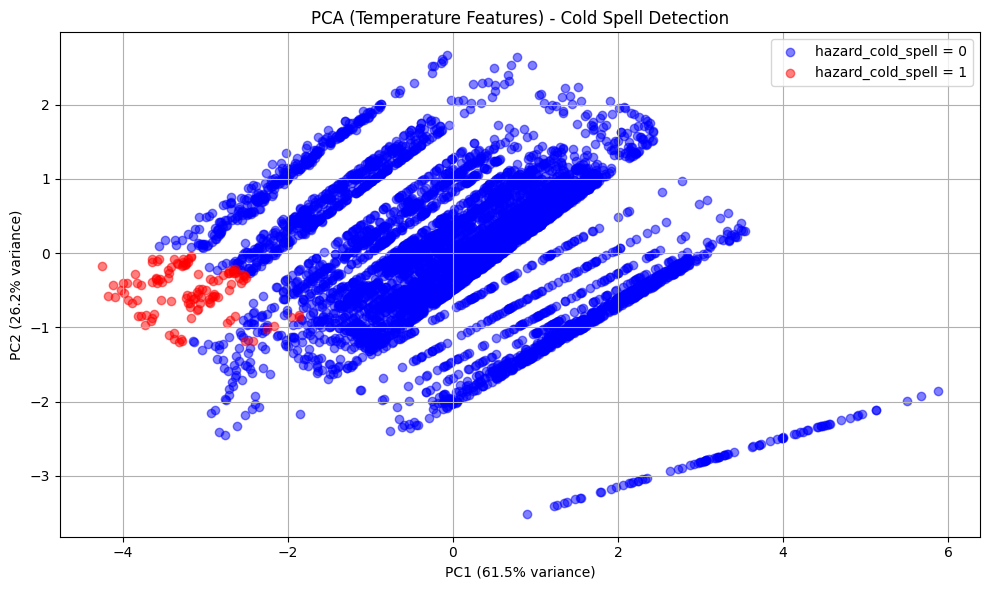

✅ تعداد Cold Spell: 117
✅ تعداد عادی: 6075


In [14]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 🎯 انتخاب ویژگی‌های دمایی
features = ['t2m', 't2m_anom', 'GDD']

# حذف ردیف‌هایی که یا ویژگی یا برچسب ندارن
df_temp = df.dropna(subset=features + ['hazard_cold_spell']).copy()

# ⚖️ استانداردسازی
X_scaled = StandardScaler().fit_transform(df_temp[features])

# 🔄 اجرای PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
explained = pca.explained_variance_ratio_ * 100  # درصد واریانس

# 📦 ترکیب با برچسب‌ها
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'], index=df_temp.index)
df_pca['hazard_cold_spell'] = df_temp['hazard_cold_spell'].astype(int)

# 📊 ترسیم
plt.figure(figsize=(10, 6))
for label in [0, 1]:
    subset = df_pca[df_pca['hazard_cold_spell'] == label]
    plt.scatter(subset['PC1'], subset['PC2'],
                c='blue' if label == 0 else 'red',
                alpha=0.5,
                label=f'hazard_cold_spell = {label}')

plt.title('PCA (Temperature Features) - Cold Spell Detection')
plt.xlabel(f'PC1 ({explained[0]:.1f}% variance)')
plt.ylabel(f'PC2 ({explained[1]:.1f}% variance)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# 🔎 آماری
print("✅ تعداد Cold Spell:", (df_pca['hazard_cold_spell'] == 1).sum())
print("✅ تعداد عادی:", (df_pca['hazard_cold_spell'] == 0).sum())


In [15]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier

# 🎯 ویژگی‌های انتخاب‌شده بر اساس تحلیل‌های پیشین (بهار - خوزستان)
features = ['spi_seasonal', 'tp', 't2m', 't2m_anom', 'tp_anom',
            'swvl1_anom', 'swvl2_anom', 'GDD']
target_col = 'hazard_drought'

# 🧹 داده‌های آموزش: فقط سطرهایی که همه‌ی ویژگی‌ها و برچسب دارند
df_train = df.dropna(subset=features + [target_col]).copy()
X_train = df_train[features]
y_train = df_train[target_col].astype(int)

# ⚙️ آموزش مدل XGBoost
model = XGBClassifier(
    max_depth=4,
    n_estimators=100,
    learning_rate=0.1,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42
)
model.fit(X_train, y_train)

# 📦 داده‌های بدون برچسب
df_unlabeled = df[df[target_col].isna() & df[features].notna().all(axis=1)].copy()
X_unlabeled = df_unlabeled[features]

# 🔮 پیش‌بینی احتمال خشکسالی
proba = model.predict_proba(X_unlabeled)[:, 1]

# 🎯 اعمال آستانه اعتماد برای برچسب‌گذاری مطمئن
df.loc[X_unlabeled.index, target_col] = np.where(
    proba >= 0.90, 1,
    np.where(proba <= 0.10, 0, np.nan)
)

# 📊 بررسی آماری
n_total = df.shape[0]
n_pos = (df[target_col] == 1).sum()
n_neg = (df[target_col] == 0).sum()
n_unlabeled = df[target_col].isna().sum()

print("✅ مجموع:", n_total)
print("✅ مثبت (خشکسالی):", n_pos)
print("✅ منفی (نرمال):", n_neg)
print("❔ بدون برچسب:", n_unlabeled)

# 💾 ذخیره فایل نهایی
output_file = "/content/spring_drought_pseudolabeled_" + file_name
df.to_csv(output_file, index=False)
print("📦 خروجی ذخیره شد:", output_file)


✅ مجموع: 6192
✅ مثبت (خشکسالی): 1831
✅ منفی (نرمال): 3067
❔ بدون برچسب: 1294


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [03:24:45] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


📦 خروجی ذخیره شد: /content/spring_drought_pseudolabeled_SPRINGnw.csv


In [16]:
import pandas as pd
from xgboost import XGBClassifier
from google.colab import files

# 🔧 آستانه‌های اطمینان
THRESHOLD_HIGH = 0.9
THRESHOLD_LOW = 0.1

# 🎯 مخاطرات و ویژگی‌های مرتبط
hazards_features = {
    'hazard_drought': ['spi_seasonal', 'tp', 't2m_anom'],
    'hazard_heatwave': ['t2m', 't2m_anom', 'GDD'],
    'hazard_cold_spell': ['t2m', 't2m_anom'],
    'hazard_rain_deficit': ['tp', 'spi_seasonal']
}

# ⚙️ تابع آموزش و برچسب‌گذاری
def train_and_refine(df, label, features):
    print(f"\n🚀 شروع فرآیند برای {label}")

    df_train = df.dropna(subset=features + [label])
    if df_train[label].nunique() < 2:
        print(f"⚠️ پرش از {label} (تنوع برچسب ندارد)")
        return df

    X_train = df_train[features]
    y_train = df_train[label].astype(int)

    model = XGBClassifier(max_depth=3, n_estimators=100,
                          use_label_encoder=False, eval_metric='logloss')
    model.fit(X_train, y_train)

    df_unlabeled = df[df[label].isna() & df[features].notna().all(axis=1)].copy()
    if df_unlabeled.empty:
        print("ℹ️ هیچ ردیف بدون برچسب و کامل وجود ندارد.")
        return df

    X_unlabeled = df_unlabeled[features]
    probs = model.predict_proba(X_unlabeled)[:, 1]

    assigned = 0
    for idx, p in zip(df_unlabeled.index, probs):
        if p >= THRESHOLD_HIGH:
            df.at[idx, label] = 1
            assigned += 1
        elif p <= THRESHOLD_LOW:
            df.at[idx, label] = 0
            assigned += 1

    print(f"✅ {assigned} نمونه برای {label} با اطمینان بالا برچسب‌گذاری شد.")
    return df

# 🔁 اجرا برای همه برچسب‌ها
for hazard, features in hazards_features.items():
    missing = [f for f in features + [hazard] if f not in df.columns]
    if missing:
        print(f"❌ پرش از {hazard}: ستون‌های ناقص {missing}")
        continue
    df = train_and_refine(df, hazard, features)

# 💾 ذخیره و دانلود فایل نهایی
output_file = "/content/pseudolabeled_final_" + file_name
df.to_csv(output_file, index=False)
print("📁 فایل نهایی ذخیره شد:", output_file)




🚀 شروع فرآیند برای hazard_drought
✅ 1294 نمونه برای hazard_drought با اطمینان بالا برچسب‌گذاری شد.

🚀 شروع فرآیند برای hazard_heatwave
ℹ️ هیچ ردیف بدون برچسب و کامل وجود ندارد.

🚀 شروع فرآیند برای hazard_cold_spell
ℹ️ هیچ ردیف بدون برچسب و کامل وجود ندارد.

🚀 شروع فرآیند برای hazard_rain_deficit


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [03:24:46] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [03:24:46] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [03:24:46] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [03:24:46] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


ℹ️ هیچ ردیف بدون برچسب و کامل وجود ندارد.
📁 فایل نهایی ذخیره شد: /content/pseudolabeled_final_SPRINGnw.csv


In [17]:
# بررسی وضعیت داده‌های بدون برچسب اما کامل برای هر مخاطره
for hazard, feats in hazards_features.items():
    condition = df[hazard].isna() & df[feats].notna().all(axis=1)
    count = condition.sum()
    print(f"{hazard}: {count} ردیف بدون برچسب و کامل وجود دارد.")


hazard_drought: 0 ردیف بدون برچسب و کامل وجود دارد.
hazard_heatwave: 0 ردیف بدون برچسب و کامل وجود دارد.
hazard_cold_spell: 0 ردیف بدون برچسب و کامل وجود دارد.
hazard_rain_deficit: 0 ردیف بدون برچسب و کامل وجود دارد.


In [18]:
import pandas as pd
from google.colab import files



# 🔍 شمارش تعداد مقادیر NaN در هر ستون
nan_counts = df.isna().sum()

# 🧹 فقط ستون‌هایی که حداقل یک NaN دارند
nan_counts = nan_counts[nan_counts > 0]

# 📊 نمایش نتایج
print("تعداد مقادیر NaN در هر ستون:")
print(nan_counts)


تعداد مقادیر NaN در هر ستون:
sst            6192
lai_hv_anom    1032
dtype: int64


In [19]:
# فقط ستون‌های عددی (ویژگی‌های اقلیمی) را انتخاب کن
features = df.select_dtypes(include='number').drop(columns=[
    'hazard_drought', 'hazard_rain_deficit', 'hazard_heatwave',
    'hazard_cold_spell', 'hazard_hot_and_dry',
    'hazard_radiation_deficit', 'hazard_temperature_accumulation_deficit'
], errors='ignore')

# حذف سطرهای دارای NaN
features_clean = features.dropna()

# نمایش شکل نهایی
print(f"شکل نهایی داده‌ها برای PCA: {features_clean.shape}")


شکل نهایی داده‌ها برای PCA: (0, 38)


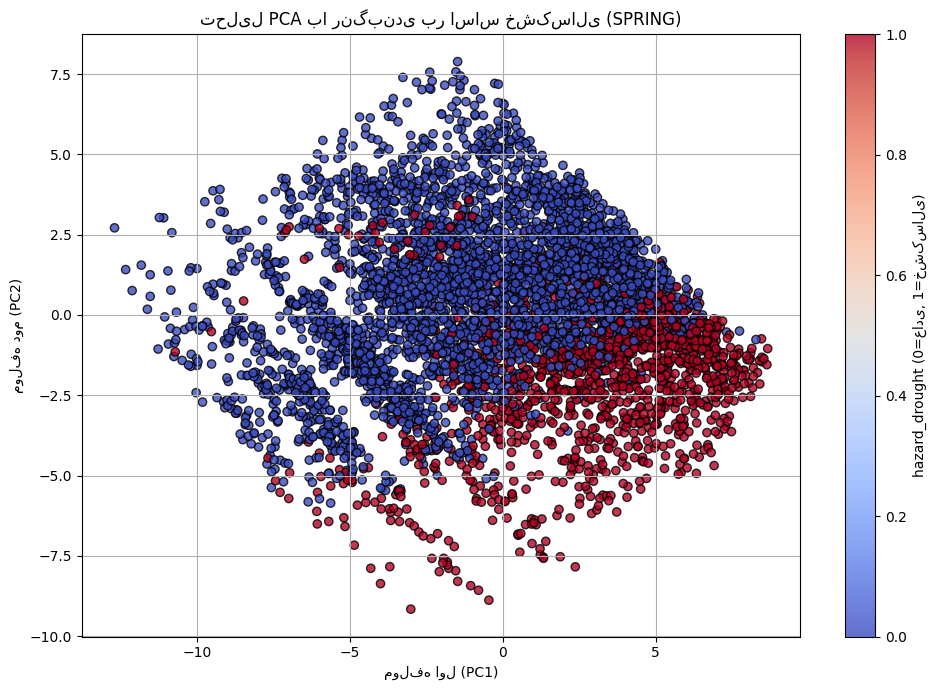

In [20]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from google.colab import files


# ❌ ستون‌هایی که نمی‌خوایم در PCA باشن (برچسب‌ها)
exclude = [
    'hazard_drought', 'hazard_rain_deficit', 'hazard_heatwave',
    'hazard_cold_spell', 'hazard_hot_and_dry',
    'hazard_radiation_deficit', 'hazard_temperature_accumulation_deficit'
]

# ✅ فقط ستون‌های عددی مفید
features = df.select_dtypes(include='number').drop(columns=exclude, errors='ignore')

# 🧹 حذف ستون‌هایی که بیشتر از ۲۰٪ داده‌ی گمشده دارن
valid_columns = features.columns[features.isna().mean() < 0.2]
features = features[valid_columns]

# 🚿 حذف ردیف‌های ناقص
features_clean = features.dropna()

# ⚖️ نرمال‌سازی
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_clean)

# 🔻 اجرای PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 🎯 ساخت DataFrame با مؤلفه‌ها و برچسب خشکسالی
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df['hazard_drought'] = df.loc[features_clean.index, 'hazard_drought'].values

# 🧹 حذف ردیف‌هایی که برچسب ندارند (NaN)
pca_df = pca_df.dropna(subset=['hazard_drought'])

# 🎨 رسم خروجی با رنگ‌بندی بر اساس خشکسالی
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    pca_df['PC1'], pca_df['PC2'],
    c=pca_df['hazard_drought'],
    cmap='coolwarm', edgecolor='k', alpha=0.8
)
plt.title("تحلیل PCA با رنگ‌بندی بر اساس خشکسالی (SPRING)")
plt.xlabel("مولفه اول (PC1)")
plt.ylabel("مولفه دوم (PC2)")
plt.colorbar(label='hazard_drought (0=عادی, 1=خشکسالی)')
plt.grid(True)
plt.tight_layout()
plt.show()


✅ تعداد رکوردهای بدون NaN: 6192


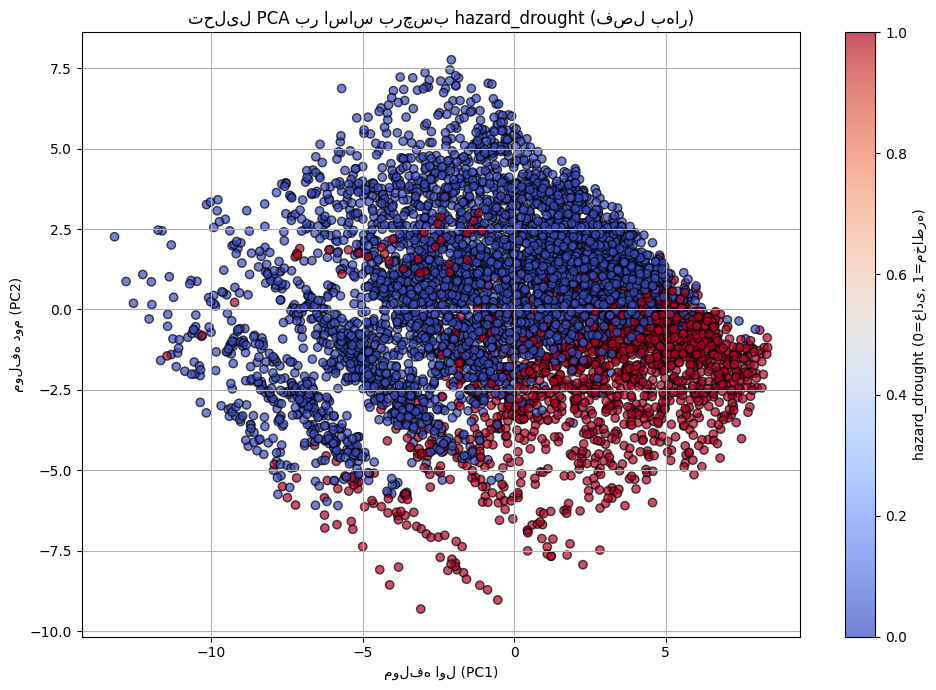

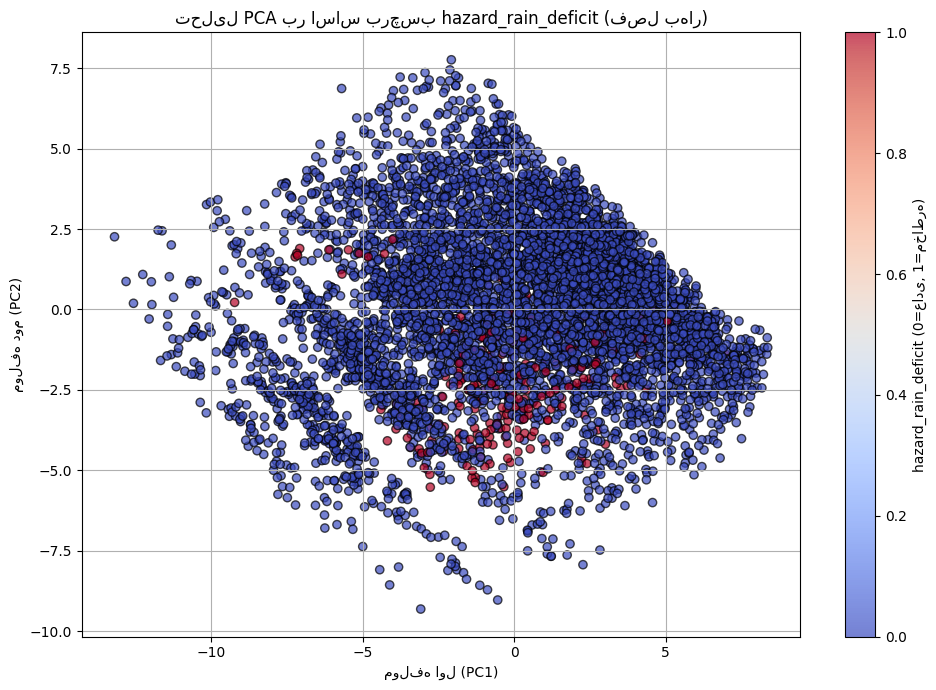

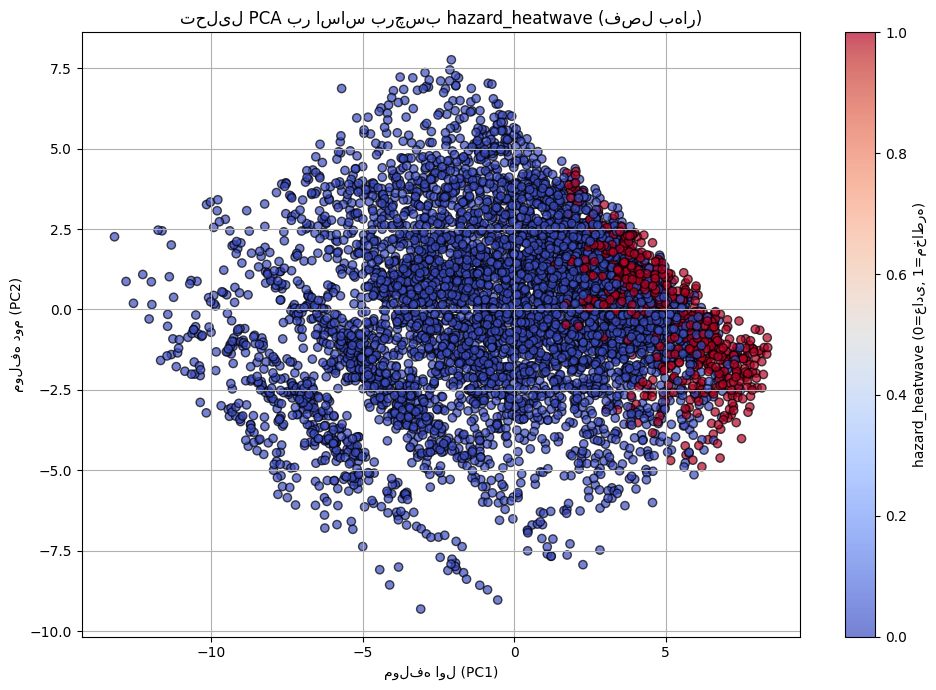

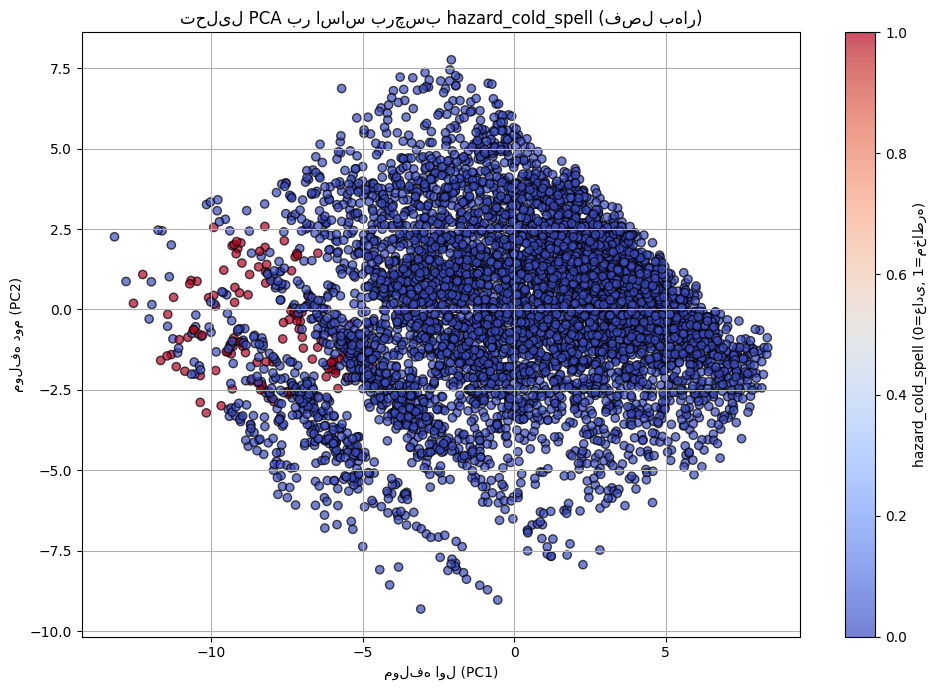

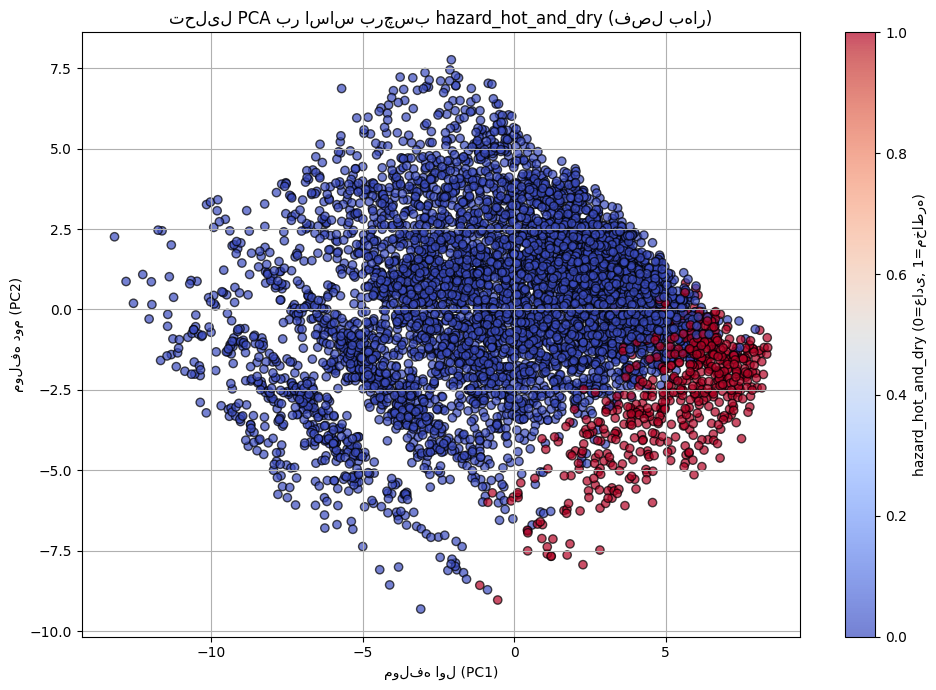

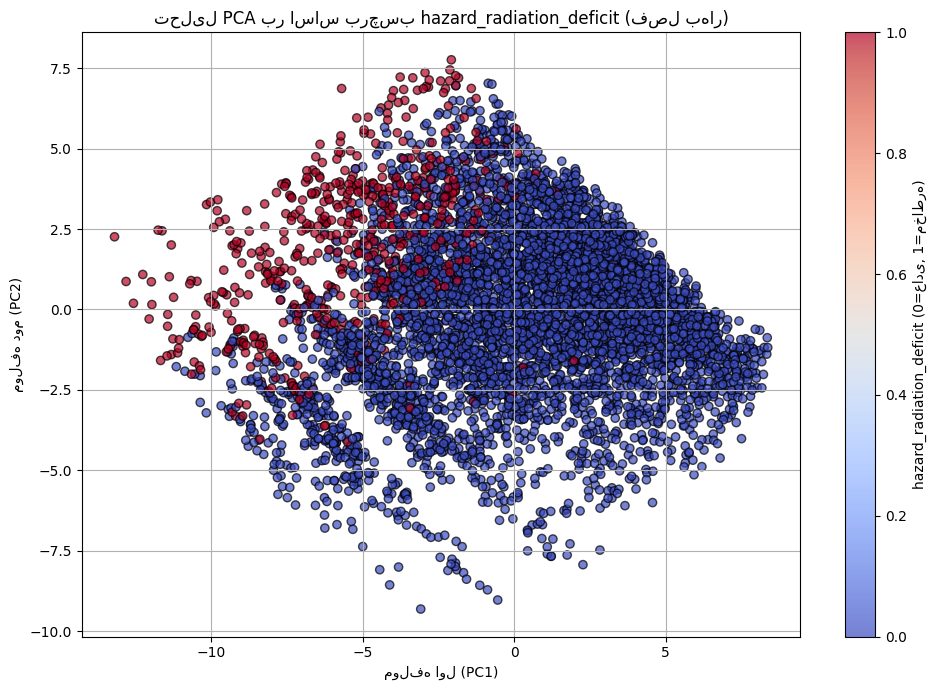

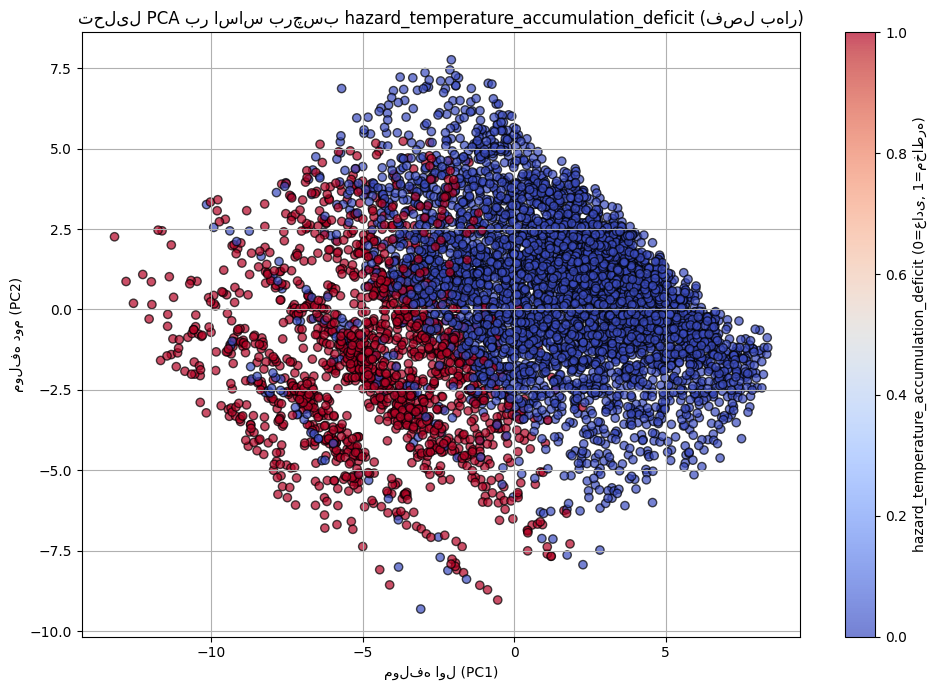

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from google.colab import files



# 🎯 برچسب‌های اقلیمی
hazard_labels = [
    'hazard_drought',
    'hazard_rain_deficit',
    'hazard_heatwave',
    'hazard_cold_spell',
    'hazard_hot_and_dry',
    'hazard_radiation_deficit',
    'hazard_temperature_accumulation_deficit'
]

# 🧹 حذف ستون‌های غیرضروری در صورت وجود
drop_columns = ['sst', 'hazard_drought_prob', 'lai_lv_anom', 'lai_hv_anom']
df = df.drop(columns=[col for col in drop_columns if col in df.columns], errors='ignore')

# ✅ فقط ستون‌های عددی به جز برچسب‌ها
feature_cols = df.select_dtypes(include='number').columns.difference(hazard_labels)
features = df[feature_cols]

# 🧹 حذف ردیف‌هایی که NaN دارند
features_clean = features.dropna()
print(f"✅ تعداد رکوردهای بدون NaN: {features_clean.shape[0]}")

# ⚖️ نرمال‌سازی
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_clean)

# 🔻 اجرای PCA دو مؤلفه‌ای
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)
df_pca = pd.DataFrame(pca_result, columns=['PC1', 'PC2'], index=features_clean.index)

# 🧩 اتصال برچسب‌ها به داده PCA
df_combined = pd.concat([df_pca, df.loc[features_clean.index, hazard_labels]], axis=1)

# 🎨 ترسیم هر برچسب به‌صورت جداگانه
for label in hazard_labels:
    if label not in df_combined.columns:
        print(f"⚠️ برچسب {label} در داده‌ها موجود نیست.")
        continue

    plt.figure(figsize=(10, 7))
    scatter = plt.scatter(
        df_combined['PC1'], df_combined['PC2'],
        c=df_combined[label],
        cmap='coolwarm',
        edgecolor='k',
        alpha=0.7
    )
    plt.colorbar(scatter, label=f'{label} (0=عادی, 1=مخاطره)')
    plt.xlabel('مولفه اول (PC1)')
    plt.ylabel('مولفه دوم (PC2)')
    plt.title(f'تحلیل PCA بر اساس برچسب {label} (فصل بهار)')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [22]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from google.colab import files

# 🧹 حذف ستون‌های غیرضروری
exclude_cols = ['year', 'latitude', 'longitude', 'region']
exclude_cols += [col for col in df.columns if col.startswith('hazard_')]
exclude_cols += [col for col in df.columns if col.endswith('_prob')]

# 🧠 انتخاب ویژگی‌های عددی
features = df.drop(columns=exclude_cols, errors='ignore').select_dtypes(include='number')
features_clean = features.dropna()

print(f"✅ رکوردهای بدون NaN در ویژگی‌ها: {features_clean.shape[0]}")

# ⚖️ نرمال‌سازی داده‌ها
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_clean)

# 🔁 آموزش مدل و پیش‌بینی احتمال برای هر برچسب
for label_col in df.columns:
    if label_col.startswith("hazard_") and not label_col.endswith("_prob"):
        y = df[label_col]

        # فیلتر داده‌های دارای برچسب و ویژگی‌های کامل
        valid_idx = features_clean.index.intersection(y.dropna().index)
        if len(valid_idx) < 10:
            print(f"⚠️ داده کافی برای آموزش {label_col} وجود ندارد.")
            continue

        print(f"▶ آموزش مدل برای: {label_col} ({len(valid_idx)} نمونه)")

        X_train = X_scaled[np.isin(features_clean.index, valid_idx)]
        y_train = y.loc[valid_idx].astype(int)

        model = XGBClassifier(max_depth=3, n_estimators=100, eval_metric='logloss', use_label_encoder=False)
        model.fit(X_train, y_train)

        # پیش‌بینی احتمال فقط برای رکوردهای کامل
        probs = model.predict_proba(X_scaled)[:, 1]
        df.loc[features_clean.index, f"{label_col}_prob"] = probs

# 💾 ذخیره فایل نهایی
output_file = "/content/spring_with_probs.csv"
df.to_csv(output_file, index=False)
print(f"✅ فایل ذخیره شد: {output_file}")





✅ رکوردهای بدون NaN در ویژگی‌ها: 6192
▶ آموزش مدل برای: hazard_drought (6192 نمونه)


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [03:24:53] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


▶ آموزش مدل برای: hazard_rain_deficit (6192 نمونه)


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [03:24:53] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


▶ آموزش مدل برای: hazard_heatwave (6192 نمونه)
▶ آموزش مدل برای: hazard_hot_and_dry (6192 نمونه)


...

▶ آموزش مدل برای: hazard_cold_spell (6192 نمونه)
▶ آموزش مدل برای: hazard_radiation_deficit (6192 نمونه)


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [03:24:54] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [03:24:54] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


▶ آموزش مدل برای: hazard_temperature_accumulation_deficit (6192 نمونه)


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [03:24:54] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


✅ فایل ذخیره شد: /content/spring_with_probs.csv


In [23]:
import pandas as pd
from google.colab import files


# 🎯 تنظیم بازه‌های ناسازگاری
low_threshold = 0.3
high_threshold = 0.7

# 🔎 بررسی تناقض برای هر برچسب
for col in df.columns:
    if col.startswith("hazard_") and not col.endswith("_prob"):
        prob_col = col + "_prob"
        if prob_col in df.columns:
            label = df[col]
            prob = df[prob_col]

            # فقط ردیف‌هایی بررسی شوند که برچسب و احتمال را هر دو دارند
            valid = label.notna() & prob.notna()

            contradiction_mask = (
                ((label == 0) & (prob > high_threshold)) |
                ((label == 1) & (prob < low_threshold))
            ) & valid

            count = contradiction_mask.sum()
            print(f"🔍 تناقض در '{col}': {count} مورد")


🔍 تناقض در 'hazard_drought': 0 مورد
🔍 تناقض در 'hazard_rain_deficit': 0 مورد
🔍 تناقض در 'hazard_heatwave': 0 مورد
🔍 تناقض در 'hazard_hot_and_dry': 0 مورد
🔍 تناقض در 'hazard_cold_spell': 0 مورد
🔍 تناقض در 'hazard_radiation_deficit': 0 مورد
🔍 تناقض در 'hazard_temperature_accumulation_deficit': 0 مورد


In [24]:
import pandas as pd
from google.colab import files



# 🧹 ستون‌هایی که می‌خوایم حذف کنیم اگر وجود داشته باشن
columns_to_drop = ['sst', 'hazard_drought_prob', 'lai_lv_anom', 'lai_hv_anom']
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns], errors='ignore')

# 💾 ذخیره فایل پاک‌سازی‌شده
output_file = "spring_cleaned.csv"
df.to_csv(output_file, index=False)
print("✅ ستون‌های ناخواسته حذف شدند.")



✅ ستون‌های ناخواسته حذف شدند.


In [25]:
from google.colab import files

# ✅ لیست نهایی فایل‌های واقعی موجود با پسوند nw
output_files = [
    "labeled_SPRINGnw.csv",
    "spring_cleaned.csv",
    "gdd_deficit_SPRINGnw.csv",
    "spring_drought_pseudolabeled_SPRINGnw.csv",
    "SPRINGnw.csv",
    "cold_spell_SPRINGnw.csv",
    "radiation_deficit_SPRINGnw.csv",
    "pseudolabeled_final_SPRINGnw.csv",
    "spring_with_probs.csv",
    "rain_deficit_SPRINGnw.csv",
    "heatwave_SPRINGnw.csv",
    "hot_and_dry_SPRINGnw.csv"
]

# ⬇️ دانلود فایل‌ها
for f in output_files:
    try:
        files.download(f)
    except Exception as e:
        print(f"❌ دانلود نشد: {f} ({e})")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
import os

# 📂 لیست همه فایل‌های موجود در پوشه جاری (معمولاً /content در Colab)
files_in_content = os.listdir('/content')

# 📄 فقط فایل‌هایی که پسوند CSV دارند
csv_files = [f for f in files_in_content if f.endswith('.csv')]

# 🖨️ نمایش
print("📁 فایل‌های CSV موجود:")
for f in csv_files:
    print("-", f)


📁 فایل‌های CSV موجود:
- hot_and_dry_SPRINGnw.csv
- spring_cleaned.csv
- heatwave_SPRINGnw.csv
- SPRINGnw.csv
- labeled_SPRINGnw.csv
- spring_drought_pseudolabeled_SPRINGnw.csv
- cold_spell_SPRINGnw.csv
- spring_with_probs.csv
- radiation_deficit_SPRINGnw.csv
- gdd_deficit_SPRINGnw.csv
- pseudolabeled_final_SPRINGnw.csv
- rain_deficit_SPRINGnw.csv


In [27]:
import pandas as pd

# بارگذاری فایل نهایی که شامل احتمال‌هاست
df_check = pd.read_csv("spring_with_probs.csv")

# چک کردن کامل بودن ستون‌های برچسب و احتمال
labels = [
    'hazard_drought', 'hazard_rain_deficit', 'hazard_heatwave',
    'hazard_hot_and_dry', 'hazard_cold_spell',
    'hazard_radiation_deficit', 'hazard_temperature_accumulation_deficit'
]

for label in labels:
    prob_col = label + "_prob"
    print(f"\n🔎 بررسی برچسب: {label}")
    print(f"✅ تعداد مقدار برچسب‌خورده (0 یا 1): {(df_check[label].isin([0, 1])).sum()}")
    print(f"📊 میانگین احتمال: {df_check[prob_col].mean():.3f}")
    print(f"📌 تعداد NaN در احتمال: {df_check[prob_col].isna().sum()}")



🔎 بررسی برچسب: hazard_drought
✅ تعداد مقدار برچسب‌خورده (0 یا 1): 6192
📊 میانگین احتمال: 0.299
📌 تعداد NaN در احتمال: 0

🔎 بررسی برچسب: hazard_rain_deficit
✅ تعداد مقدار برچسب‌خورده (0 یا 1): 6192
📊 میانگین احتمال: 0.040
📌 تعداد NaN در احتمال: 0

🔎 بررسی برچسب: hazard_heatwave
✅ تعداد مقدار برچسب‌خورده (0 یا 1): 6192
📊 میانگین احتمال: 0.092
📌 تعداد NaN در احتمال: 0

🔎 بررسی برچسب: hazard_hot_and_dry
✅ تعداد مقدار برچسب‌خورده (0 یا 1): 6192
📊 میانگین احتمال: 0.089
📌 تعداد NaN در احتمال: 0

🔎 بررسی برچسب: hazard_cold_spell
✅ تعداد مقدار برچسب‌خورده (0 یا 1): 6192
📊 میانگین احتمال: 0.019
📌 تعداد NaN در احتمال: 0

🔎 بررسی برچسب: hazard_radiation_deficit
✅ تعداد مقدار برچسب‌خورده (0 یا 1): 6192
📊 میانگین احتمال: 0.093
📌 تعداد NaN در احتمال: 0

🔎 بررسی برچسب: hazard_temperature_accumulation_deficit
✅ تعداد مقدار برچسب‌خورده (0 یا 1): 6192
📊 میانگین احتمال: 0.250
📌 تعداد NaN در احتمال: 0


In [28]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ✨ فقط ستون‌های عددی (به‌جز برچسب‌ها)
exclude = [
    'hazard_drought', 'hazard_rain_deficit', 'hazard_heatwave',
    'hazard_cold_spell', 'hazard_hot_and_dry',
    'hazard_radiation_deficit', 'hazard_temperature_accumulation_deficit'
]
features = df.select_dtypes(include='number').drop(columns=exclude, errors='ignore')

# ❌ حذف ستون‌هایی که بیش از 20٪ داده‌ی گمشده دارند
valid_columns = features.columns[features.isna().mean() < 0.2]
features = features[valid_columns]

# 🚿 حذف سطرهای ناقص
features_clean = features.dropna()

# ✅ استانداردسازی
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_clean)

# 🔄 اجرای PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 🎯 اضافه کردن PC1 و PC2 به df
df.loc[features_clean.index, "PC1"] = X_pca[:, 0]
df.loc[features_clean.index, "PC2"] = X_pca[:, 1]


In [29]:
import pandas as pd
import numpy as np

# 📦 اگر هنوز df بارگذاری نشده، این خط را فعال کن:
# df = pd.read_csv("نام_فایل_اصلی_تو.csv")

# 🎯 برچسب‌هایی که بررسی می‌کنیم
hazard_cols = [
    'hazard_drought',
    'hazard_rain_deficit',
    'hazard_heatwave',
    'hazard_hot_and_dry',
    'hazard_cold_spell',
    'hazard_radiation_deficit',
    'hazard_temperature_accumulation_deficit'
]

# 🧠 تحلیل آماری برای هر برچسب
results = []

for col in hazard_cols:
    if col not in df.columns:
        continue
    for label in [0, 1]:
        subset = df[df[col] == label]
        if subset.empty:
            continue
        pc1_mean = subset["PC1"].mean() if "PC1" in subset else np.nan
        pc1_std = subset["PC1"].std() if "PC1" in subset else np.nan
        pc2_mean = subset["PC2"].mean() if "PC2" in subset else np.nan
        pc2_std = subset["PC2"].std() if "PC2" in subset else np.nan
        results.append({
            "hazard": col,
            "label": label,
            "count": len(subset),
            "PC1_mean": round(pc1_mean, 2),
            "PC1_std": round(pc1_std, 2),
            "PC2_mean": round(pc2_mean, 2),
            "PC2_std": round(pc2_std, 2)
        })

# 📊 تبدیل به DataFrame و نمایش
summary_df = pd.DataFrame(results)
pd.set_option('display.max_rows', None)
print("📌 تحلیل آماری برچسب‌ها:\n")
print(summary_df)


📌 تحلیل آماری برچسب‌ها:

                                     hazard  label  count  PC1_mean  PC1_std  \
0                            hazard_drought      0   4339     -1.23     3.77   
1                            hazard_drought      1   1853      2.88     3.29   
2                       hazard_rain_deficit      0   5945      0.02     4.14   
3                       hazard_rain_deficit      1    247     -0.41     2.55   
4                           hazard_heatwave      0   5623     -0.58     3.81   
5                           hazard_heatwave      1    569      5.72     1.70   
6                        hazard_hot_and_dry      0   5638     -0.56     3.81   
7                        hazard_hot_and_dry      1    554      5.68     2.00   
8                         hazard_cold_spell      0   6075      0.17     3.92   
9                         hazard_cold_spell      1    117     -9.07     1.86   
10                 hazard_radiation_deficit      0   5614      0.61     3.69   
11             

In [30]:
!pip install cartopy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 99.1 MB/s eta 0:00:00


📌 Spatial Map for: hazard_drought


/usr/local/lib/python3.11/dist-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.11/dist-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.11/dist-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


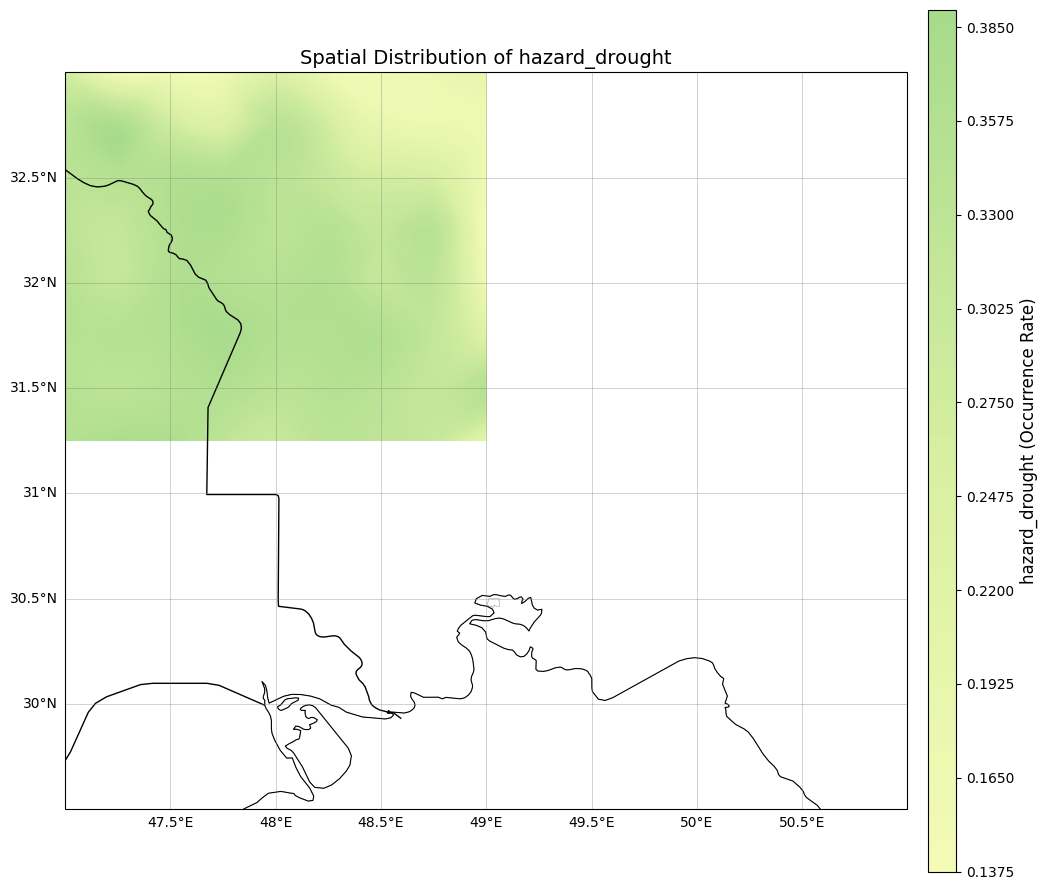

📌 Spatial Map for: hazard_rain_deficit


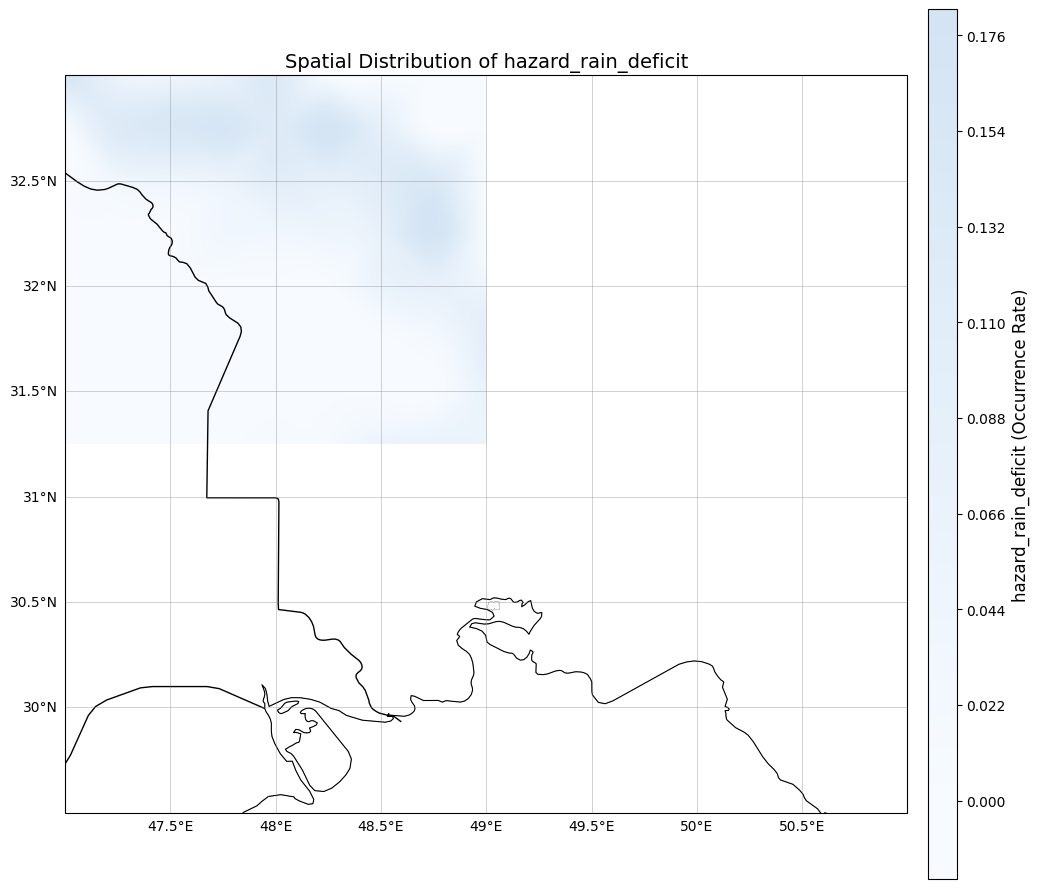

📌 Spatial Map for: hazard_heatwave


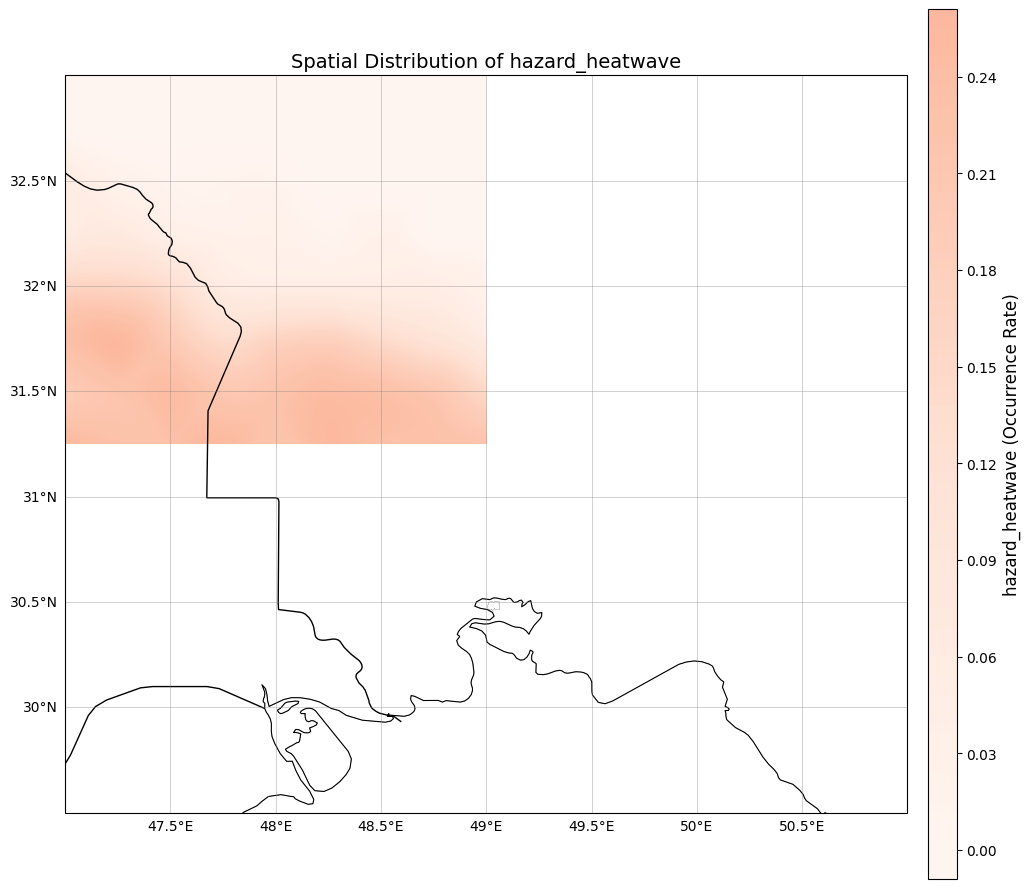

📌 Spatial Map for: hazard_cold_spell


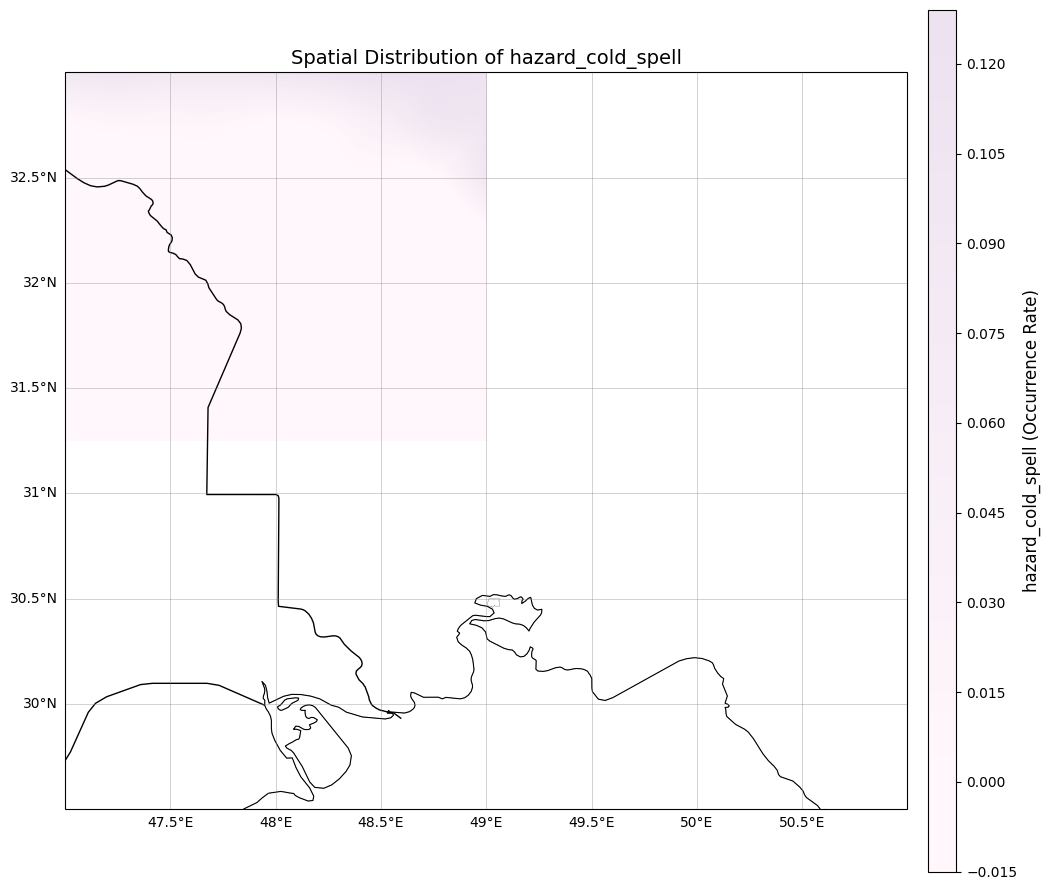

📌 Spatial Map for: hazard_hot_and_dry


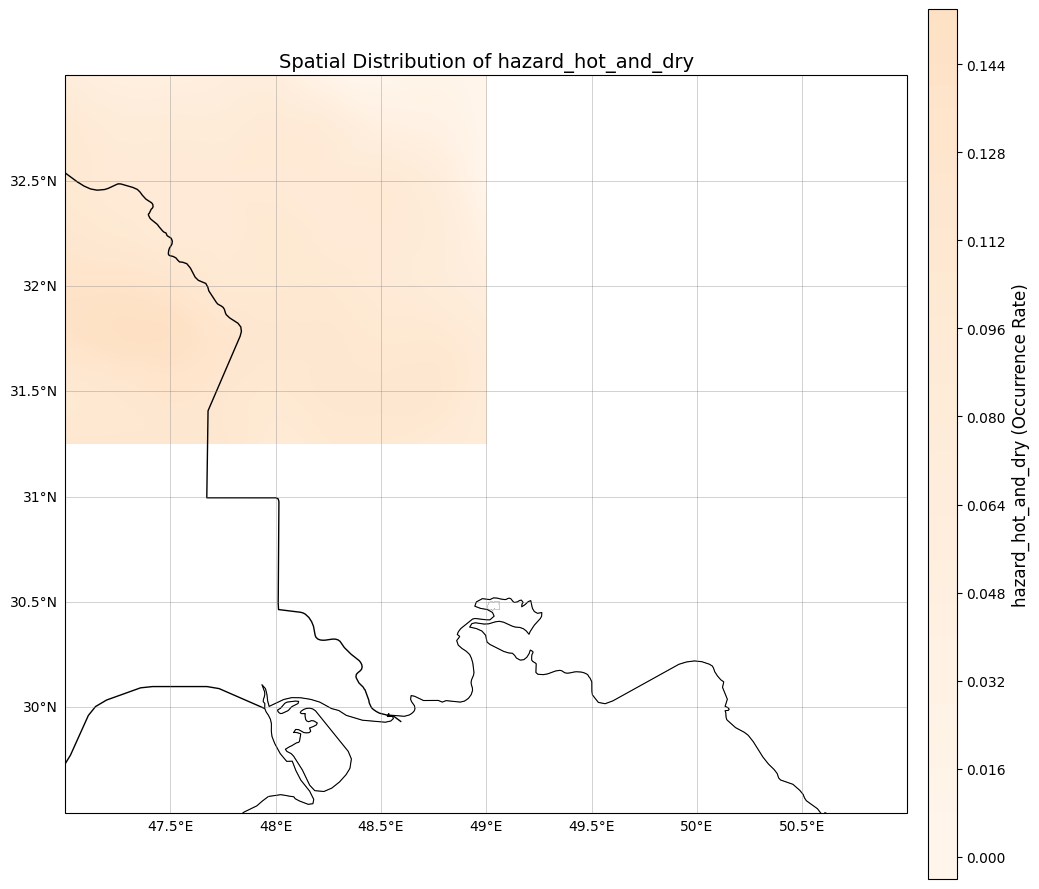

📌 Spatial Map for: hazard_radiation_deficit


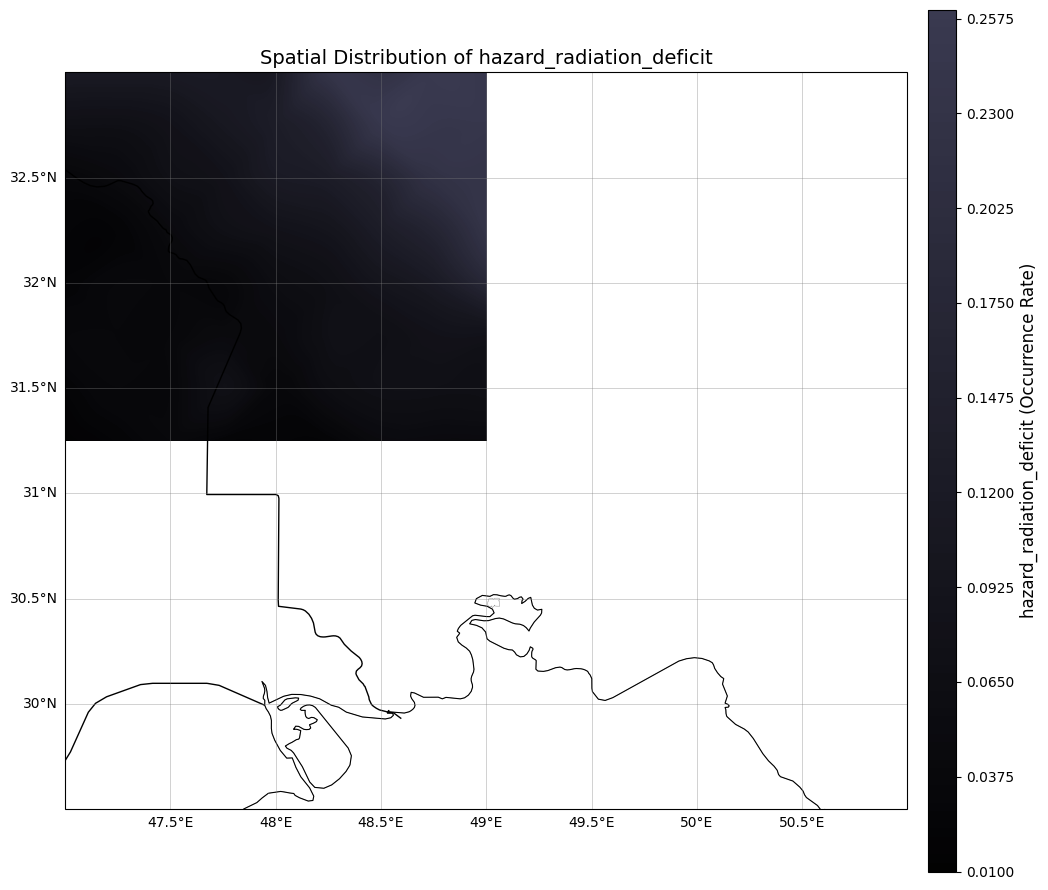

📌 Spatial Map for: hazard_temperature_accumulation_deficit


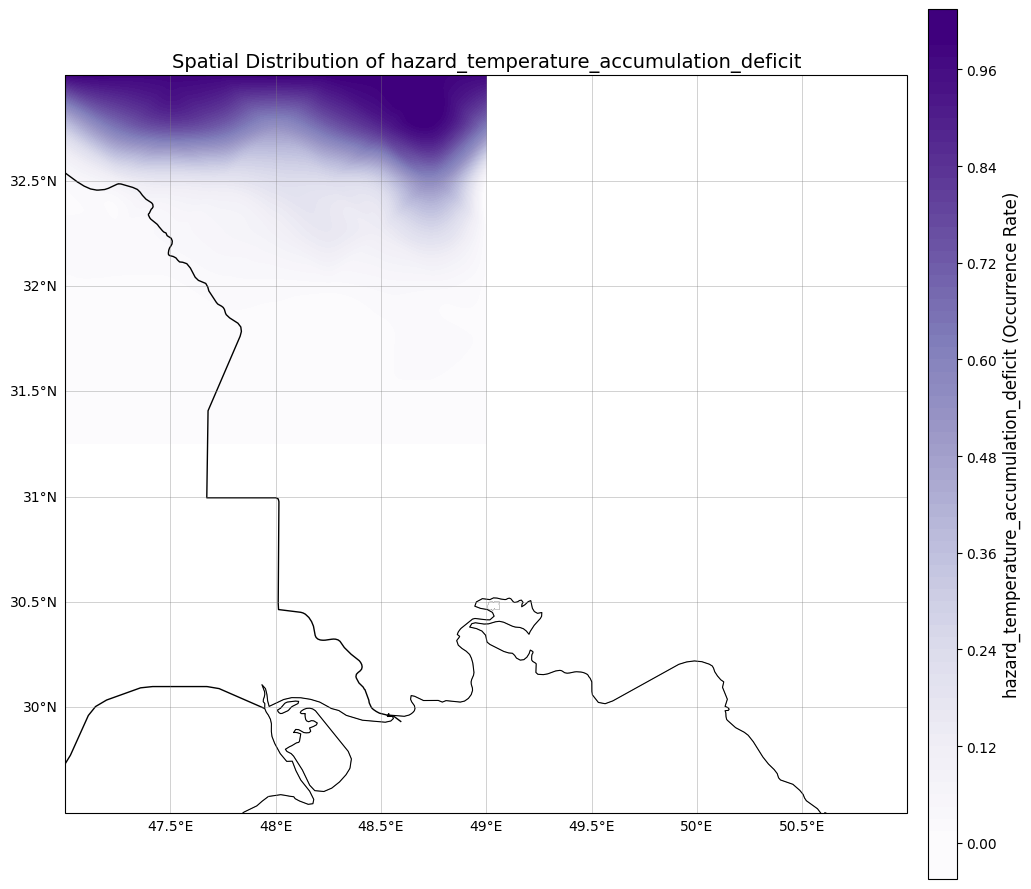

In [31]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import griddata
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# نام برچسب‌ها و Colormap مخصوص هرکدام
hazard_labels = [
    'hazard_drought',
    'hazard_rain_deficit',
    'hazard_heatwave',
    'hazard_cold_spell',
    'hazard_hot_and_dry',
    'hazard_radiation_deficit',
    'hazard_temperature_accumulation_deficit'
]

# هر برچسب Colormap مخصوص دارد
hazard_cmaps = {
    'hazard_drought': 'YlGn',
    'hazard_rain_deficit': 'Blues',
    'hazard_heatwave': 'Reds',
    'hazard_cold_spell': 'PuBuGn',
    'hazard_hot_and_dry': 'Oranges',
    'hazard_radiation_deficit': 'bone',
    'hazard_temperature_accumulation_deficit': 'Purples'
}

for hazard_label in hazard_labels:
    print(f"📌 Spatial Map for: {hazard_label}")

    # داده‌های سالم
    df_map = df[df[hazard_label].isin([0, 1]) & df['latitude'].notna() & df['longitude'].notna()].copy()
    if df_map.empty:
        print(f"⚠️ No data for {hazard_label}\n")
        continue

    grouped = df_map.groupby(['latitude', 'longitude'])[hazard_label].mean().reset_index()

    # گرید
    lon_grid = np.linspace(grouped['longitude'].min(), grouped['longitude'].max(), 300)
    lat_grid = np.linspace(grouped['latitude'].min(), grouped['latitude'].max(), 300)
    grid_lon, grid_lat = np.meshgrid(lon_grid, lat_grid)

    # درونیابی
    grid_values = griddata(
        (grouped['longitude'], grouped['latitude']),
        grouped[hazard_label],
        (grid_lon, grid_lat),
        method='cubic'
    )

    # رسم نقشه
    fig = plt.figure(figsize=(11, 9))
    ax = plt.axes(projection=ccrs.PlateCarree())

    # مقیاس colorbar (برای همه برچسب‌ها ثابت است)
    vmin = 0
    vmax = 1

    # colormap مخصوص هر برچسب
    cmap = hazard_cmaps.get(hazard_label, 'coolwarm')

    contour = ax.contourf(
        grid_lon, grid_lat, grid_values, 100,
        cmap=cmap,
        vmin=vmin, vmax=vmax,
        transform=ccrs.PlateCarree()
    )

    ax.add_feature(cfeature.BORDERS, linewidth=1)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
    ax.add_feature(cfeature.LAND, facecolor='none', edgecolor='gray', linewidth=0.3)

    ax.set_extent([47.0, 51.0, 29.5, 33.0], crs=ccrs.PlateCarree())
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False

    cbar = plt.colorbar(contour, orientation='vertical', pad=0.02, aspect=30)
    cbar.set_label(f'{hazard_label} (Occurrence Rate)', fontsize=12)
    plt.title(f'Spatial Distribution of {hazard_label}', fontsize=14)
    plt.tight_layout()
    plt.show()


In [32]:
import pandas as pd
from google.colab import files

# 🔖 لیست برچسب‌های نهایی موردنظر
hazard_labels = [
    'hazard_drought',
    'hazard_rain_deficit',
    'hazard_heatwave',
    'hazard_cold_spell',
    'hazard_hot_and_dry',
    'hazard_radiation_deficit',
    'hazard_temperature_accumulation_deficit'
]

# ✅ فقط ستون‌هایی که در df موجود هستن نگه دار
available_labels = [col for col in hazard_labels if col in df.columns]

# 📁 مسیر فایل خروجی
output_excel_path = "/content/final_hazards_spring_nw.xlsx"

# 📦 ذخیره به اکسل با همه ستون‌ها
df.to_excel(output_excel_path, index=False)

# ⬇️ دانلود فایل
files.download(output_excel_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
import pandas as pd
from google.colab import files

# 🔄 خواندن فایل اصلی CSV (مطمئن باش اسم فایل دقیقا همینه)
df_original = pd.read_csv("SPRING.csv")

# 📁 مسیر خروجی اکسل
excel_output_path = "/content/SPRING_original.xlsx"

# 💾 ذخیره به فرمت اکسل
df_original.to_excel(excel_output_path, index=False)

# ⬇️ دانلود
files.download(excel_output_path)


FileNotFoundError: [Errno 2] No such file or directory: 'SPRING.csv'